# 03 · Signatures — embryonic-development module scores & Gate 2 (scoped manifold)

Module scores on the **scoped embryonic manifold** (cycling lobe removed in 02). Deliverable maps
show **raw** per-cell scores (reference style); smoothed scores drive the geography statistics.
Gate 2 asks whether the embryonic pattern appears: Gast & pSom co-vary at the hub/root, Crest is the
inverse terminal gradient high at differentiated arm tips.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd, scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars'); pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
print('scoped embryonic manifold:', adata.shape[0], 'cells | milestones:', list(adata.obs['milestones'].cat.categories))
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')

scoped embryonic manifold: 1967 cells | milestones: ['0', '127', '134', '14', '183', '53', '93', '96', '98']
smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.80
  Crest_sm vs Gast_sm: r = -0.77
  Crest_sm vs pSom_sm: r = -0.66


### Gate 2 — module geography and pseudotime order
Gast & pSom co-vary (positive smoothed r) with Crest opposed; Crest rises to a differentiated arm
tip (terminal). Embryonic pattern present -> Gate 2 = GO. Whether the two arms are a *competitive*
Gast-vs-pSom bifurcation is Gate 3's question (04_correlation).

In [4]:
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('pseudotime gradient (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho={rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
print('Gate 2: embryonic modules present, Gast/pSom co-vary, Crest terminal -> GO')

pseudotime gradient (Spearman rho on smoothed):
  Gast_sm: rho=-0.388
  pSom_sm: rho=-0.593
  Crest_sm: rho=+0.615
Crest-high decile mean pseudotime = 0.76 (terminal if ~1)
Gate 2: embryonic modules present, Gast/pSom co-vary, Crest terminal -> GO


### Per-module signature figures + colorbars (deliverable, RAW scores)

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


<ipython-input-5-2def903d35e0>:12: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb=plt.colorbar(ax.collections[0],cax=cax); cb.ax.tick_params(which='both',size=0)
<ipython-input-5-2def903d35e0>:12: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb=plt.colorbar(ax.collections[0],cax=cax); cb.ax.tick_params(which='both',size=0)
<ipython-input-5-2def903d35e0>:12: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb=plt.colorbar(ax.collections[0],cax=cax); cb.ax.tick_params(which='both',size=0)


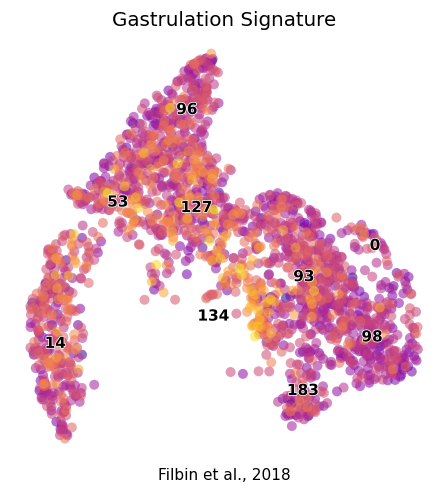

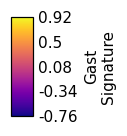

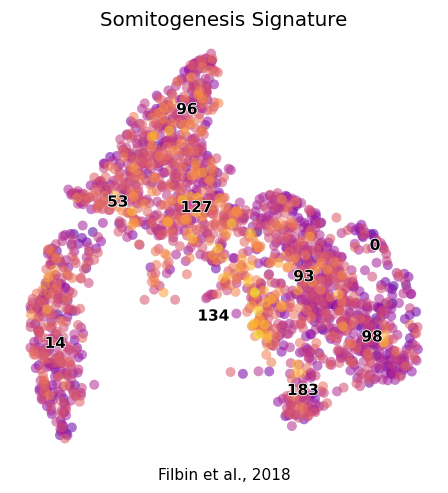

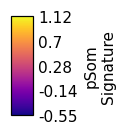

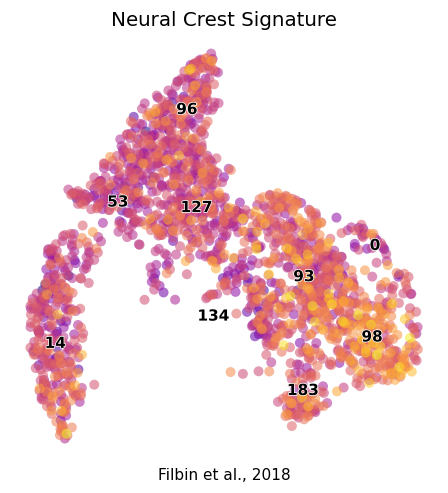

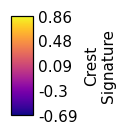

In [5]:
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(1,1,figsize=(5,5))
    sc.pl.umap(adata, color=m, cmap='plasma', alpha=.55, size=170, colorbar_loc=None, frameon=False, show=False, ax=ax)
    sc.pl.umap(adata, color='milestones', size=170, alpha=0, legend_loc='on data',
               legend_fontoutline=1, frameon=False, show=False, ax=ax)
    ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title(titles[m], size=13)
    ax.text(.5,-.05,'Filbin et al., 2018', ha='center', transform=ax.transAxes)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo,hi=float(adata.obs[m].min()),float(adata.obs[m].max()); ticks=np.round(np.linspace(lo,hi,5),2)
    fcb=plt.figure(figsize=(.66,1)); cax=fcb.add_axes([.35,.05,.3,.9])
    cb=plt.colorbar(ax.collections[0],cax=cax); cb.ax.tick_params(which='both',size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks,labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    plt.show(); print('saved', f'{m}_signature.pdf', '+ colorbar')

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad')); print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (1967, 21224)
